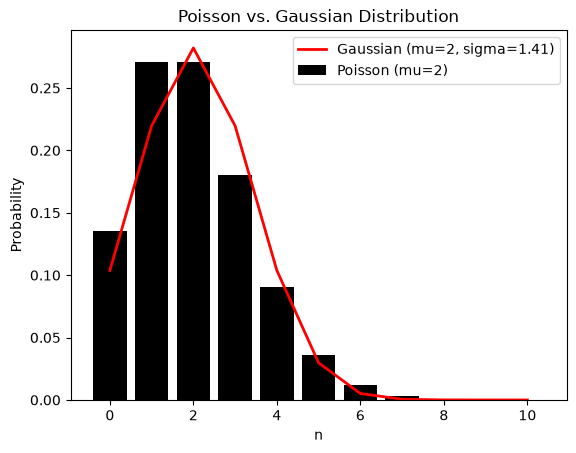

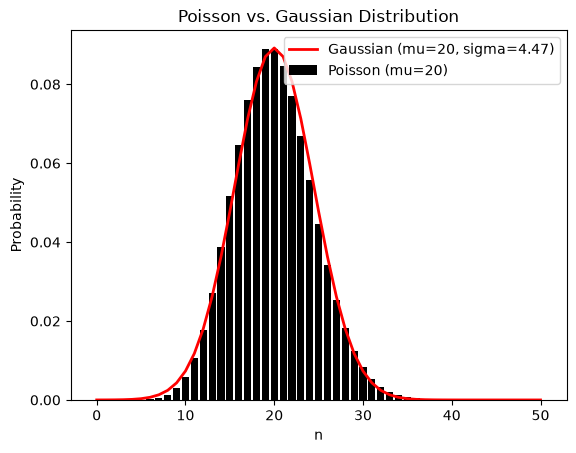

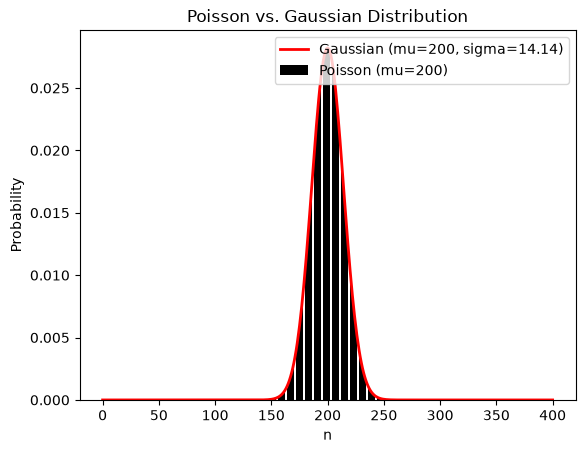

In [31]:
'Problem 2b'

import numpy as np
import scipy
from scipy.special import gammaln
import matplotlib.pyplot as plt

# Poisson Distribution

def poisson(mu, n):
    log = n * np.log(mu) - mu - gammaln(n + 1)
    return np.exp(log)

# Gaussian Distribution

def gaussian(mu, sigma, n):
    return (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-((n - mu)**2) / (2 * sigma**2))

for mu, n in [(2, np.arange(0, 11)), (20, np.arange(0, 51)), (200, np.arange(0, 401))]:
    sigma = np.sqrt(mu)
    plt.bar(n, poisson(mu, n), color='black', label=f'Poisson (mu={mu})')
    plt.plot(n, gaussian(mu, sigma, n), color = 'red', linewidth = 2, label=f'Gaussian (mu={mu}, sigma={sigma:.2f})')
    plt.xlabel('n')
    plt.ylabel('Probability')
    plt.title('Poisson vs. Gaussian Distribution')
    plt.legend(loc= 'upper right')
    plt.show()

In [32]:
'Problem 2c'

'i'

n = np.arange(0,5)

for n in [n]:
    sum = np.sum(poisson(0.5, n))
    print("Probability of observing 5 or more photons in a given interval:", f"{1 - sum:.1g}")

'ii'

from scipy.integrate import quad

f = lambda x: (1 / np.sqrt(2*np.pi)) * np.exp(-x**2 / 2)

p, error = quad(f, 6.4, np.inf)

print("Probability of observing 5 or more photons in a given interval (w/ a Gaussian approximation):", f"{p:.1g}")

Probability of observing 5 or more photons in a given interval: 0.0002
Probability of observing 5 or more photons in a given interval (w/ a Gaussian approximation): 8e-11


Best fit parameters: a = -40.783649095860014 , b = 454.1584409226281


Text(0, 0.5, 'Residuals (km/s)')

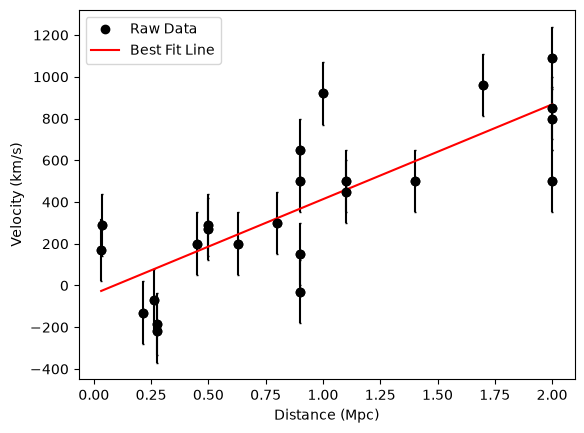

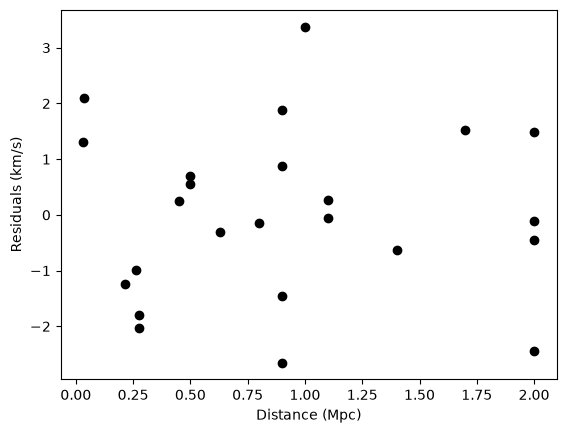

In [33]:
'Problem 3b'

sigma_i = 150 #km/s

#distance x in Mpc
x = [0.032, 0.034, 0.214, 0.263, 0.275, 0.275, 0.45, 0.5, 0.5, 0.63, 0.8,
      0.9, 0.9, 0.9, 0.9, 1.0, 1.1, 1.1, 1.4, 1.7, 2.0, 2.0, 2.0, 2.0]

#velocity in km/s
y = [170, 290, -130, -70, -185, -220, 200, 290, 270, 200, 300, -30,
      650, 150, 500, 920, 450, 500, 500, 960, 500, 850, 800, 1090]

Sx = np.sum(x) / sigma_i**2
Sy = np.sum(y) / sigma_i**2
S = len(x) / sigma_i**2
Sxy = np.sum(np.array(x) * np.array(y)) / sigma_i**2
Sxx = np.sum(np.array(x)**2) / sigma_i**2


a = ((Sxy * Sx) - (Sxx * Sy)) / (Sx**2 - (S * Sxx))
b = ((Sx * Sy) - (S * Sxy)) / (Sx**2 - (S * Sxx))

print("Best fit parameters: a =", a, ", b =", b)


y_axis = a + (b * np.array(x))

plt.errorbar(
    x, y,
    yerr=sigma_i,
    fmt='o',
    capsize=1,
    color='black'
)

plt.plot(x, y, 'o', label='Raw Data', color = 'black')
plt.plot(x, y_axis, label='Best Fit Line', color='red')
plt.xlabel('Distance (Mpc)')
plt.ylabel('Velocity (km/s)')
plt.legend(loc='upper left')

residuals = (np.array(y) - a - (b*np.array(x)))/sigma_i

plt.figure()
plt.plot(x, residuals, 'o', color='black')
plt.xlabel('Distance (Mpc)')
plt.ylabel('Residuals (km/s)')

Variance of a: 2.9e+03 , Variance of b: 2.3e+03 , Covariance of a and b: -2.1e+03 , Correlation Coefficient: -0.82


<a list of 2 text.Text objects>

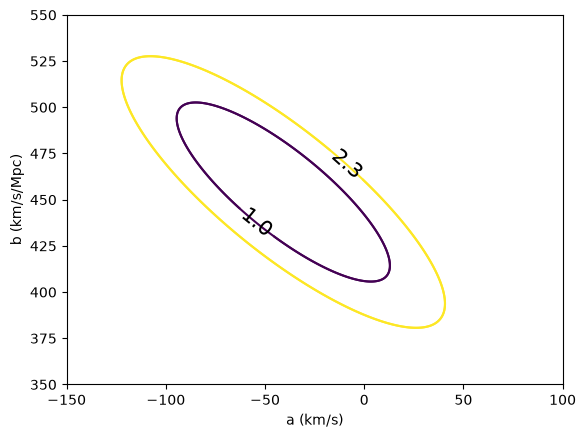

In [34]:
'Problem 3c'

#Calculating wanted values
delta = (S * Sxx) - (Sx**2)

var_b = S / delta
var_a = Sxx / delta
cov_ab = -Sx / delta
corr_coeff = cov_ab / np.sqrt(var_a * var_b)

print("Variance of a:", f"{var_a:.2g}", ", Variance of b:", f"{var_b:.2g}", ", Covariance of a and b:", f"{cov_ab:.2g}", ", Correlation Coefficient:", f"{corr_coeff:.2g}")

#Contour Plot
a_values = np.linspace(-150, 100, 1000)
b_values = np.linspace(350, 550, 1000)

A, B = np.meshgrid(a_values, b_values)

x = np.array(x)
y = np.array(y)

model = A[:, :, np.newaxis] + B[:, :, np.newaxis] * x

chi2 = np.sum((y - model)**2, axis=2) / sigma_i**2

chi2_min = np.sum((y - (a + b * x))**2) / sigma_i**2

delta_chi2 = chi2 - chi2_min

plt.contour(A, B, delta_chi2, levels=[1, 2.3])
plt.xlabel('a (km/s)')
plt.ylabel('b (km/s/Mpc)')
plt.clabel(plt.contour(A, B, delta_chi2, levels=[1, 2.3]), colors=['black', 'black'], fontsize=15)

In [35]:
'Problem 3d'

# Comparing the chi2_min to the number of degrees of freedom (N - 2 = 22) to see if the model is a good fit
print(chi2_min)

print(chi2_min / (22))

# finding alpha
rescale = np.sum((np.array(y) - (a + b * np.array(x)))**2) / 22
alpha = np.sqrt(rescale) / 150

better_chi2min = np.sum((np.array(y) - (a + b * np.array(x)))**2) / (alpha*sigma_i)**2

print("Alpha:", alpha)
print("Better Chi2_min:", better_chi2min)

53.04188294542845
2.410994679337657
Alpha: 1.552737801220044
Better Chi2_min: 22.000000000000004


Best fit parameter: b = 423.9373232316303


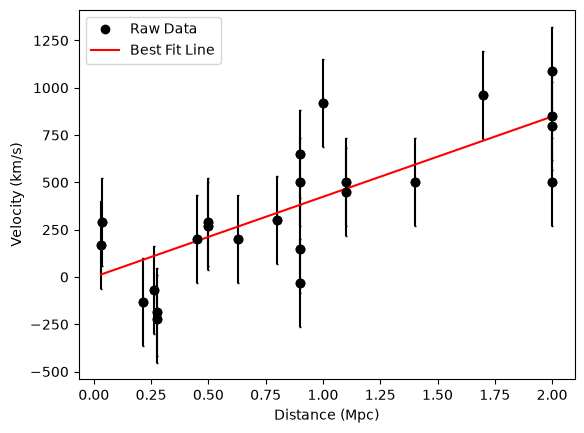

New Chi2_min: 22.238910554255558
Chi2_min difference: 0.23891055425555408
Standard deviation from 0 to a: 0.48878477293748324


In [36]:
'Problem 3d cont.'

# New best fit with rescaled sigma_i

new_sigma_i = alpha * 150 #km/s

#distance x in Mpc
x = [0.032, 0.034, 0.214, 0.263, 0.275, 0.275, 0.45, 0.5, 0.5, 0.63, 0.8,
      0.9, 0.9, 0.9, 0.9, 1.0, 1.1, 1.1, 1.4, 1.7, 2.0, 2.0, 2.0, 2.0]

#velocity in km/s
y = [170, 290, -130, -70, -185, -220, 200, 290, 270, 200, 300, -30,
      650, 150, 500, 920, 450, 500, 500, 960, 500, 850, 800, 1090]

Sx = np.sum(x) / new_sigma_i**2
Sy = np.sum(y) / new_sigma_i**2
S = len(x) / new_sigma_i**2
Sxy = np.sum(np.array(x) * np.array(y)) / new_sigma_i**2
Sxx = np.sum(np.array(x)**2) / new_sigma_i**2


b = Sxy / Sxx

print("Best fit parameter: b =", b)


y_axis = b * np.array(x)

plt.errorbar(
    x, y,
    yerr=new_sigma_i,
    fmt='o',
    capsize=1,
    color='black'
)

plt.plot(x, y, 'o', label='Raw Data', color = 'black')
plt.plot(x, y_axis, label='Best Fit Line', color='red')
plt.xlabel('Distance (Mpc)')
plt.ylabel('Velocity (km/s)')
plt.legend(loc='upper left')
plt.show()

new_chi2_min = np.sum((np.array(y) - (b * np.array(x)))**2) / new_sigma_i**2
print("New Chi2_min:", new_chi2_min)
print("Chi2_min difference:", new_chi2_min - better_chi2min)

# Std dev 0 is from a = -40.783649095860014

a0 = -40.783649095860014
new_delta = (S * Sxx) - (Sx**2)
new_std_dev_a = np.sqrt(Sxx / new_delta)
std_dev_below = np.abs(a0)/ new_std_dev_a
print("Standard deviation from 0 to a:", std_dev_below)
